<a href="https://colab.research.google.com/github/2303a51008/PYTHON-EXM/blob/main/PYTHON_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip -q install kaggle pyyaml scikit-learn pandas matplotlib pillow
print("Required libraries installed successfully.")


Required libraries installed successfully.


In [ ]:
import os
import sys
import time
import glob
import random
import shutil
import zipfile
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from collections import Counter

print("Python version:", sys.version.split()[0])
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

if not tf.config.list_physical_devices("GPU"):
    print("WARNING: No GPU detected. Enable T4 GPU in Runtime settings.")
else:
    print("GPU is ready.")

Python version: 3.13.16
TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU is ready.


In [ ]:

from google.colab import files

uploaded = files.upload()
print("Upload completed.")


Saving kaggle.json to kaggle.json
Upload completed.


In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle API configured.")

Kaggle API configured.


In [ ]:

DATA_DIR = "/content/crop_pests_data"
os.makedirs(DATA_DIR, exist_ok=True)

!kaggle datasets download -d rupankarmajumdar/crop-pests-dataset -p /content/crop_pests_data --unzip

print("Dataset download and extraction completed.")


Dataset URL: https://www.kaggle.com/datasets/rupankarmajumdar/crop-pests-dataset
License(s): MIT
100% 537M/537M [00:08<00:00, 70.1MB/s]

Dataset download and extraction completed.


In [ ]:
# Load the dataset configuration from data.yaml
with open(os.path.join(DATA_DIR, "data.yaml"), "r") as f:
    config = yaml.safe_load(f)

# Read class names from data.yaml
names = config["names"]

if isinstance(names, dict):
    class_names = [str(names[k]) for k in sorted(names, key=lambda x: int(x))]
else:
    class_names = [str(name) for name in names]

NUM_CLASSES = len(class_names)
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

# Find the folder containing a split's images
def find_split_images(split_names):
    for split in split_names:
        matches = glob.glob(
            DATA_DIR + "/**/" + split + "/images",
            recursive=True
        )
        if matches:
            return matches[0]
    return None

train_images_dir = find_split_images(["train"])
val_images_dir = find_split_images(["valid", "val"])
test_images_dir = find_split_images(["test"])

print("Train folder:", train_images_dir)
print("Validation folder:", val_images_dir)
print("Test folder:", test_images_dir)

if not all([train_images_dir, val_images_dir, test_images_dir]):
    raise FileNotFoundError(
        "Could not locate all split folders. Inspect the dataset folders."
    )

Train folder: /content/crop_pests_data/train/images
Validation folder: /content/crop_pests_data/valid/images
Test folder: /content/crop_pests_data/test/images


In [ ]:
def make_image_dataframe(images_dir):
    labels_dir = os.path.join(
        os.path.dirname(images_dir), "labels"
    )
    records = []

    image_paths = sorted([
        p for p in glob.glob(images_dir + "/**/*", recursive=True)
        if os.path.isfile(p) and p.lower().endswith(IMAGE_EXTS)
    ])

    for image_path in image_paths:
        label_path = os.path.join(
            labels_dir,
            os.path.splitext(os.path.basename(image_path))[0] + ".txt"
        )

        if not os.path.isfile(label_path):
            continue

        object_ids = []
        with open(label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                try:
                    class_id = int(parts[0])
                    if 0 <= class_id < NUM_CLASSES:
                        object_ids.append(class_id)
                except ValueError:
                    continue

        if not object_ids:
            continue

        # Most frequent annotated class becomes the image label
        selected_id = Counter(object_ids).most_common(1)[0][0]

        records.append({
            "filename": image_path,
            "label": class_names[selected_id]
        })

    return pd.DataFrame(records)

train_df = make_image_dataframe(train_images_dir)
val_df = make_image_dataframe(val_images_dir)
test_df = make_image_dataframe(test_images_dir)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Total usable images:", len(train_df) + len(val_df) + len(test_df))

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError(
        "A split contains no labelled images. Check folder structure."
    )

print("\nTraining class distribution:")
print(train_df["label"].value_counts().reindex(class_names, fill_value=0))

Training images: 11499
Validation images: 1095
Test images: 546
Total usable images: 13140

Training class distribution:
label
Ants            1032
Bees            1098
Beetles          857
Caterpillars     909
Earthworms       714
Earwigs          942
Grasshoppers    1044
Moths           1059
Slugs            797
Snails          1079
Wasps           1008
Weevils          960
Name: count, dtype: int64


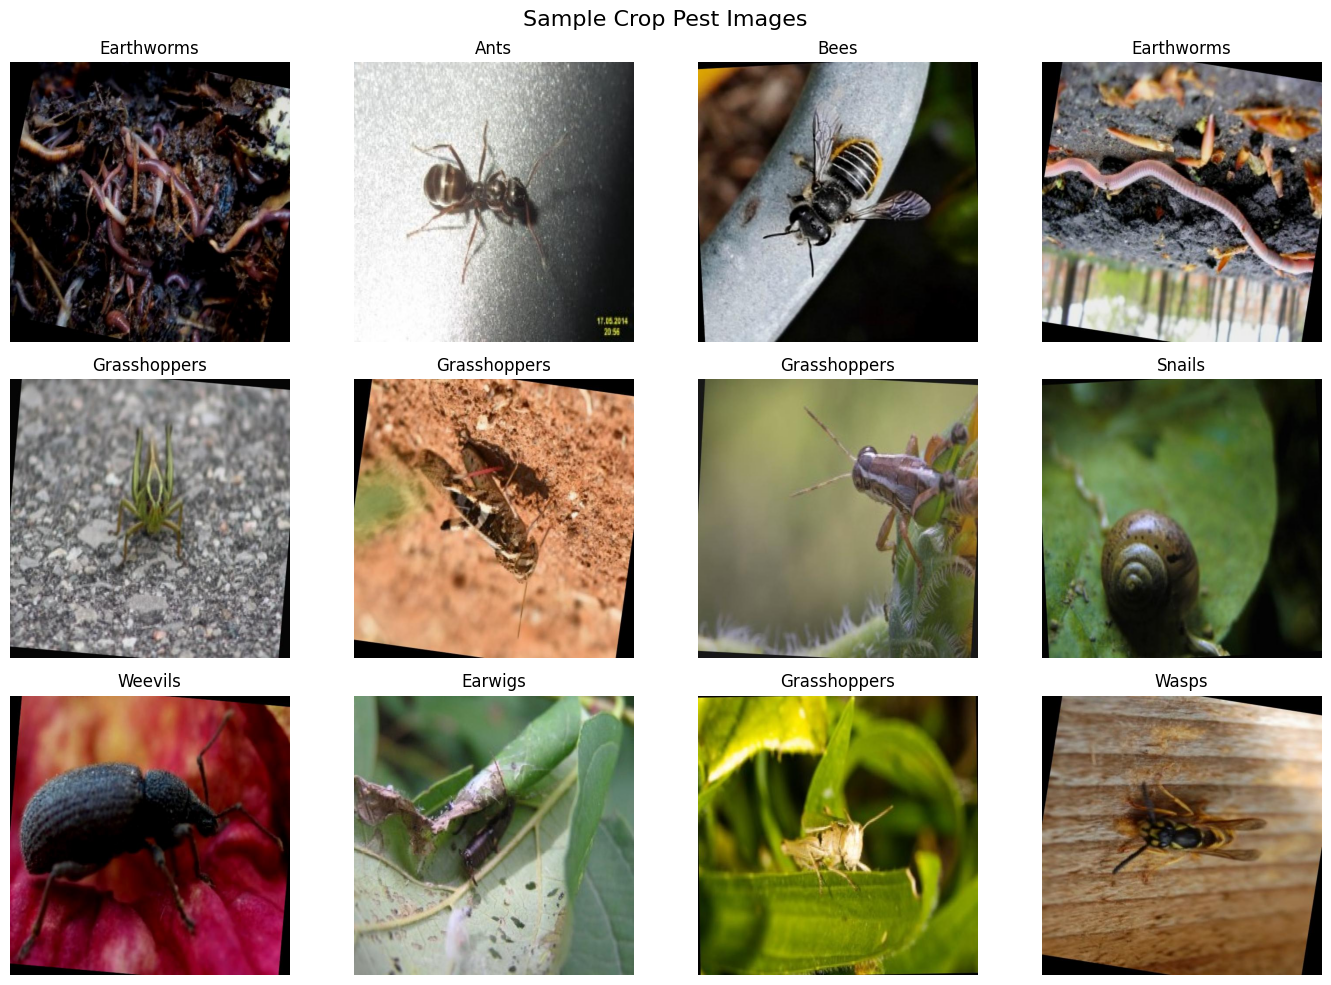

In [ ]:
sample_df = train_df.sample(
    n=min(12, len(train_df)),
    random_state=42
).reset_index(drop=True)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for i, ax in enumerate(axes):
    ax.axis("off")
    if i < len(sample_df):
        row = sample_df.iloc[i]
        image = Image.open(row["filename"]).convert("RGB")
        ax.imshow(image)
        ax.set_title(row["label"])

plt.suptitle("Sample Crop Pest Images", fontsize=16)
plt.tight_layout()
plt.savefig(
    "/content/sample_pest_images.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

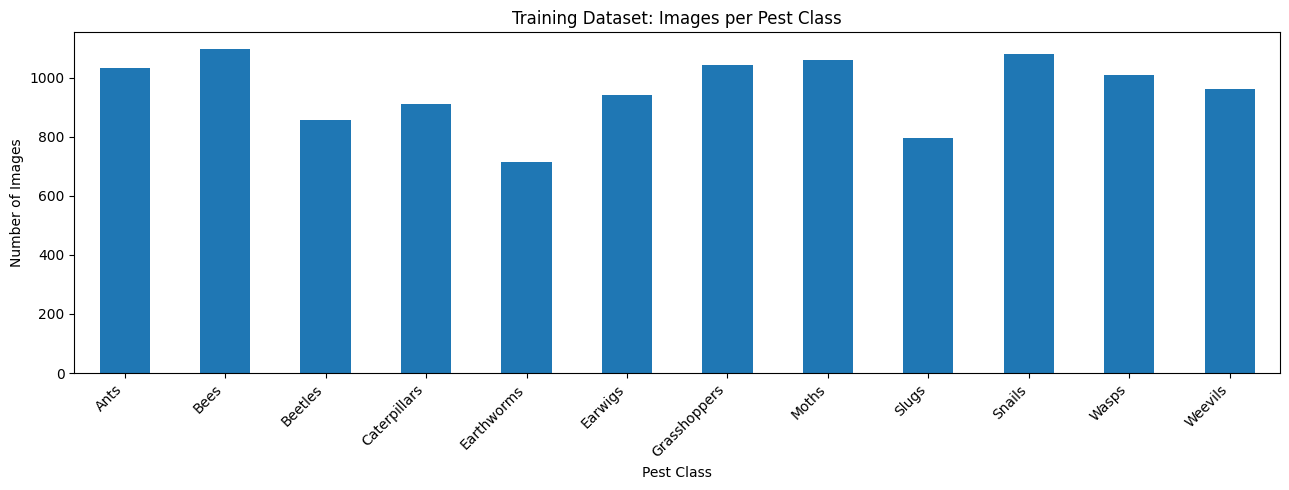

In [ ]:
counts = train_df["label"].value_counts().reindex(
    class_names, fill_value=0
)

plt.figure(figsize=(13, 5))
counts.plot(kind="bar")
plt.title("Training Dataset: Images per Pest Class")
plt.xlabel("Pest Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("/content/class_distribution.png", dpi=150)
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

eval_datagen = ImageDataGenerator()

train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col="filename",
    y_col="label",
    classes=class_names,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_gen = eval_datagen.flow_from_dataframe(
    val_df,
    x_col="filename",
    y_col="label",
    classes=class_names,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_gen = eval_datagen.flow_from_dataframe(
    test_df,
    x_col="filename",
    y_col="label",
    classes=class_names,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("All image generators are ready.")
print("Class mapping:", train_gen.class_indices)

Found 11499 validated image filenames belonging to 12 classes.
Found 1095 validated image filenames belonging to 12 classes.
Found 546 validated image filenames belonging to 12 classes.
All image generators are ready.
Class mapping: {'Ants': 0, 'Bees': 1, 'Beetles': 2, 'Caterpillars': 3, 'Earthworms': 4, 'Earwigs': 5, 'Grasshoppers': 6, 'Moths': 7, 'Slugs': 8, 'Snails': 9, 'Wasps': 10, 'Weevils': 11}


In [ ]:
from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import tensorflow as tf

base_eff = EfficientNetB4(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_eff.trainable = False

x = GlobalAveragePooling2D()(base_eff.output)
x = Dropout(0.4)(x)
outputs = Dense(NUM_CLASSES, activation="softmax")(x)

efficientnet_model = Model(base_eff.input, outputs)

efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model.summary()

71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │      1,296 │ stem_conv_pad[0]… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        192 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        432 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        192 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 48)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 48)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 12)  │        588 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 48)  │        624 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 48)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      1,152 │ block1a_se_excit

 Total params: 17,695,339 (67.50 MB)

 Trainable params: 21,516 (84.05 KB)

 Non-trainable params: 17,673,823 (67.42 MB)

In [ ]:
callbacks_eff = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

start_eff = time.time()

history_eff = efficientnet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    callbacks=callbacks_eff,
    verbose=1
)

time_eff = time.time() - start_eff

print("EfficientNetB4 training finished.")
print("Training time in minutes:", round(time_eff / 60, 2))

Epoch 1/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 287s 332ms/step - accuracy: 0.8403 - loss: 0.5715 - val_accuracy: 0.9041 - val_loss: 0.3266 - learning_rate: 0.0010
Epoch 2/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 182s 253ms/step - accuracy: 0.8940 - loss: 0.3446 - val_accuracy: 0.9032 - val_loss: 0.3114 - learning_rate: 0.0010
Epoch 3/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 178s 247ms/step - accuracy: 0.9069 - loss: 0.2926 - val_accuracy: 0.9114 - val_loss: 0.2890 - learning_rate: 0.0010
Epoch 4/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 187s 260ms/step - accuracy: 0.9116 - loss: 0.2716 - val_accuracy: 0.9068 - val_loss: 0.3001 - learning_rate: 0.0010
Epoch 5/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 182s 252ms/step - accuracy: 0.9139 - loss: 0.2624 - val_accuracy: 0.9151 - val_loss: 0.2848 - learning_rate: 0.0010
Epoch 6/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 177s 246ms/step - accuracy: 0.9193 - loss: 0.2434 - val_accuracy: 0.9187 - val_loss: 0.2895 - learning_rate: 0.0010
Epoch 7/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - accuracy

In [ ]:
base_eff.trainable = True

# Freeze all layers except the last 30 layers
for layer in base_eff.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen to protect moving statistics
for layer in base_eff.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Re-compile the model with a very low learning rate for fine-tuning
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

fine_callbacks_eff = [
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

start = time.time()

history_eff_fine = efficientnet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5,
    callbacks=fine_callbacks_eff,
    verbose=1
)

time_eff += time.time() - start

print("EfficientNetB4 fine-tuning completed.")

Epoch 1/5
719/719 ━━━━━━━━━━━━━━━━━━━━ 263s 305ms/step - accuracy: 0.9331 - loss: 0.2038 - val_accuracy: 0.9169 - val_loss: 0.2778 - learning_rate: 1.0000e-05
Epoch 2/5
719/719 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step - accuracy: 0.9409 - loss: 0.1792
Epoch 2: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
719/719 ━━━━━━━━━━━━━━━━━━━━ 181s 252ms/step - accuracy: 0.9421 - loss: 0.1761 - val_accuracy: 0.9187 - val_loss: 0.2782 - learning_rate: 1.0000e-05
Epoch 3/5
719/719 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step - accuracy: 0.9478 - loss: 0.1612
Epoch 3: ReduceLROnPlateau reducing learning rate to 3.999999989900971e-07.
719/719 ━━━━━━━━━━━━━━━━━━━━ 182s 253ms/step - accuracy: 0.9466 - loss: 0.1630 - val_accuracy: 0.9196 - val_loss: 0.2784 - learning_rate: 2.0000e-06
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.
EfficientNetB4 fine-tuning completed.


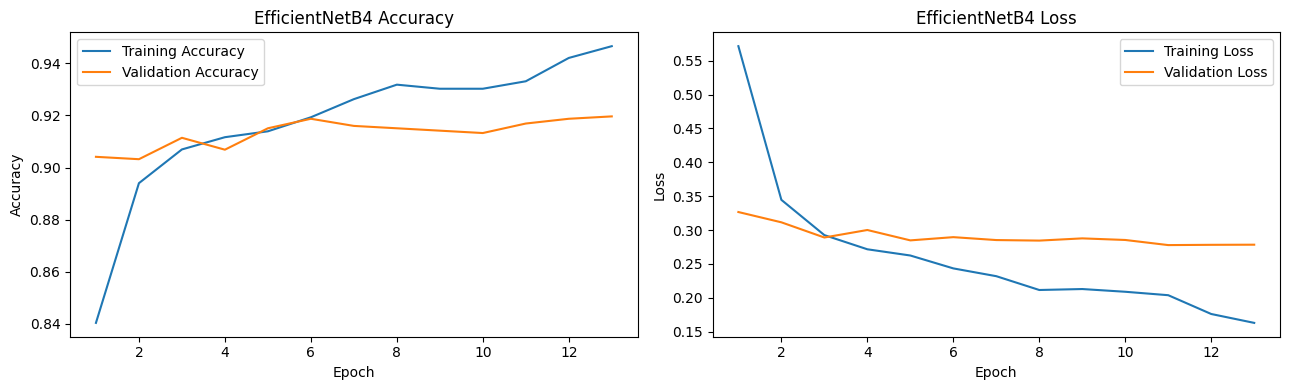

In [ ]:
def plot_history(histories, model_name, save_path):
    acc, val_acc, loss, val_loss = [], [], [], []

    for h in histories:
        acc += h.history.get("accuracy", [])
        val_acc += h.history.get("val_accuracy", [])
        loss += h.history.get("loss", [])
        val_loss += h.history.get("val_loss", [])

    epochs = range(1, len(acc) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(epochs, acc, label="Training Accuracy")
    axes[0].plot(epochs, val_acc, label="Validation Accuracy")
    axes[0].set_title(model_name + " Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(epochs, loss, label="Training Loss")
    axes[1].plot(epochs, val_loss, label="Validation Loss")
    axes[1].set_title(model_name + " Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

plot_history(
    [history_eff, history_eff_fine],
    "EfficientNetB4",
    "/content/efficientnet_training_graphs.png"
)

35/35 ━━━━━━━━━━━━━━━━━━━━ 14s 410ms/step - accuracy: 0.9194 - loss: 0.2570

Test Loss: 0.2570
Test Accuracy: 0.9194
35/35 ━━━━━━━━━━━━━━━━━━━━ 22s 361ms/step

Classification Report:
              precision    recall  f1-score   support

        Ants       0.95      0.98      0.96        54
        Bees       0.85      0.97      0.91        40
     Beetles       0.94      0.76      0.84        41
Caterpillars       0.83      0.85      0.84        46
  Earthworms       0.96      0.93      0.94        27
     Earwigs       0.89      0.81      0.85        59
Grasshoppers       0.83      0.92      0.88        38
       Moths       1.00      0.94      0.97        47
       Slugs       0.95      0.91      0.93        46
      Snails       0.92      1.00      0.96        44
       Wasps       0.96      0.96      0.96        46
     Weevils       0.97      1.00      0.98        58

    accuracy                           0.92       546
   macro avg       0.92      0.92      0.92       546
weigh

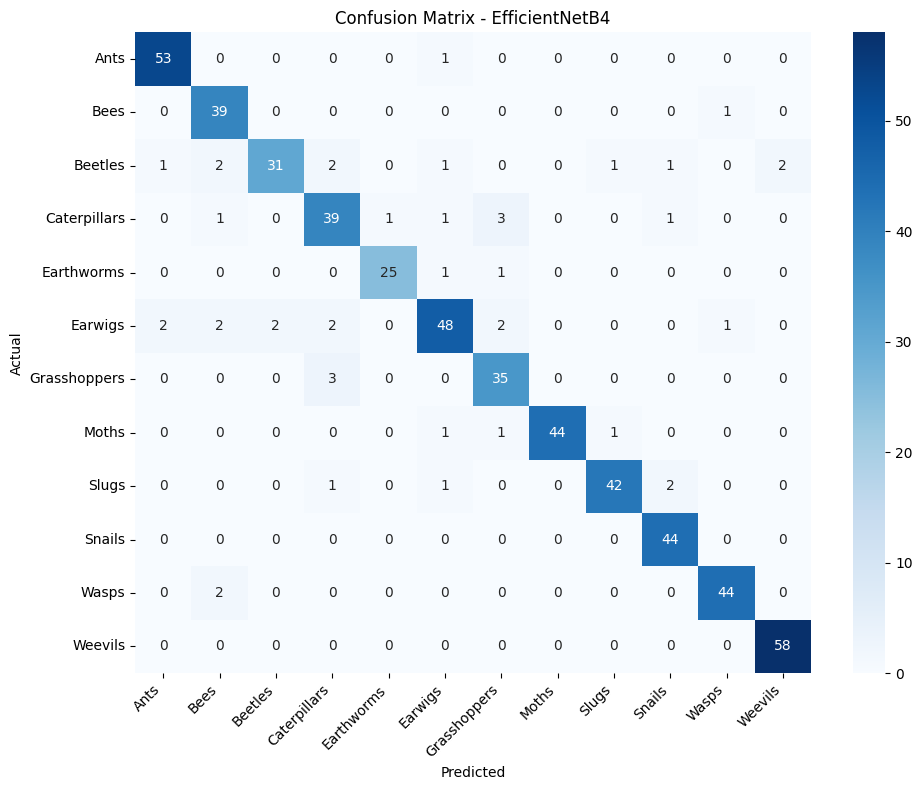

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Evaluate the model on the test generator
test_loss, test_accuracy = efficientnet_model.evaluate(test_gen, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Get predictions
test_gen.reset()
predictions = efficientnet_model.predict(test_gen, verbose=1)
y_pred = np.argmax(predictions, axis=1)
y_true = test_gen.classes

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix - EfficientNetB4")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("/content/efficientnet_confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import tensorflow as tf
import time

# 1. Define ConvNeXtTiny model structure
base_conv = ConvNeXtTiny(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_conv.trainable = False

x = GlobalAveragePooling2D()(base_conv.output)
x = Dropout(0.4)(x)
outputs_conv = Dense(NUM_CLASSES, activation="softmax")(x)

convnext_model = Model(base_conv.input, outputs_conv)

# 2. Compile the model (fixed metrics to be a list)
convnext_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# 3. Setup callbacks and fit
callbacks_conv = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

start_conv = time.time()

history_conv = convnext_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    callbacks=callbacks_conv,
    verbose=1
)

time_conv = time.time() - start_conv

print("ConvNeXtTiny training finished.")
print("Training time in minutes:", round(time_conv / 60, 2))

Epoch 1/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 217s 278ms/step - accuracy: 0.8053 - loss: 0.7070 - val_accuracy: 0.8904 - val_loss: 0.3723 - learning_rate: 0.0010
Epoch 2/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 180s 250ms/step - accuracy: 0.8919 - loss: 0.3717 - val_accuracy: 0.9050 - val_loss: 0.3234 - learning_rate: 0.0010
Epoch 3/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 188s 262ms/step - accuracy: 0.9003 - loss: 0.3236 - val_accuracy: 0.8968 - val_loss: 0.3238 - learning_rate: 0.0010
Epoch 4/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 183s 255ms/step - accuracy: 0.9092 - loss: 0.2925 - val_accuracy: 0.9014 - val_loss: 0.3155 - learning_rate: 0.0010
Epoch 5/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 185s 257ms/step - accuracy: 0.9164 - loss: 0.2733 - val_accuracy: 0.8995 - val_loss: 0.2976 - learning_rate: 0.0010
Epoch 6/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 184s 257ms/step - accuracy: 0.9214 - loss: 0.2557 - val_accuracy: 0.9114 - val_loss: 0.2921 - learning_rate: 0.0010
Epoch 7/10
719/719 ━━━━━━━━━━━━━━━━━━━━ 192s 267ms/step - accura

In [ ]:
base_conv.trainable = True

# Freeze all layers except the last 30 layers
for layer in base_conv.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen to protect moving statistics
for layer in base_conv.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Re-compile the ConvNeXt model with a very low learning rate for fine-tuning
convnext_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

fine_callbacks_conv = [
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

start = time.time()

history_conv_fine = convnext_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5,
    callbacks=fine_callbacks_conv,
    verbose=1
)

time_conv += time.time() - start

print("ConvNeXtTiny fine-tuning completed.")

Epoch 1/5
719/719 ━━━━━━━━━━━━━━━━━━━━ 244s 302ms/step - accuracy: 0.9359 - loss: 0.2046 - val_accuracy: 0.9224 - val_loss: 0.2632 - learning_rate: 1.0000e-05
Epoch 2/5
719/719 ━━━━━━━━━━━━━━━━━━━━ 197s 274ms/step - accuracy: 0.9503 - loss: 0.1593 - val_accuracy: 0.9297 - val_loss: 0.2480 - learning_rate: 1.0000e-05
Epoch 3/5
719/719 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.9599 - loss: 0.1293
Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
719/719 ━━━━━━━━━━━━━━━━━━━━ 200s 278ms/step - accuracy: 0.9603 - loss: 0.1280 - val_accuracy: 0.9306 - val_loss: 0.2507 - learning_rate: 1.0000e-05
Epoch 4/5
719/719 ━━━━━━━━━━━━━━━━━━━━ 195s 271ms/step - accuracy: 0.9678 - loss: 0.1125 - val_accuracy: 0.9324 - val_loss: 0.2436 - learning_rate: 2.0000e-06
Epoch 5/5
719/719 ━━━━━━━━━━━━━━━━━━━━ 200s 278ms/step - accuracy: 0.9710 - loss: 0.1032 - val_accuracy: 0.9342 - val_loss: 0.2405 - learning_rate: 2.0000e-06
Restoring model weights from the end of the best ep